# Trying a Decision Model Approach on a Real Dataset

Let's see how much value we can squeeze out of the decision model approach when testing against a real-life dataset.

## Setup
### Get The Data

Here I'm downloading a [public dataset that ABPDU has provided](https://abpdu.lbl.gov/resources/fermentation-bioreactor-sample-data/) to the community. One of the challenges with this dataset has been that it's literally a file dump from an AMBR250 bioreactor system. AMBR's software provides a lot of data about what the bioreactor is doing, but it's buried in a complex file system and can be hard to parse if you're not familiar with the equipment.

Let's download the whole thing and see if we can just throw it at the model and get decent results!

In [1]:
import os
import zipfile

import gdown  #helper library for downloading from Google Drive
import numpy as np
import pandas as pd
from laya import Router

import plotly.express as px
import plotly.graph_objects as go

In [ ]:
# Context page is here: https://abpdu.lbl.gov/resources/fermentation-bioreactor-sample-data/
DATA_URL = 'https://drive.google.com/file/d/1RIcJgbCbgpI_l3BLhA0vihqQze97N32S/view?usp=sharing'
DATA_DIRECTORY = 'example_data'
OUTPUT_ZIP_FILE = DATA_DIRECTORY + '.zip'

try:
    gdown.download(url=DATA_URL,output=OUTPUT_ZIP_FILE)

    print('Unzipping data...')
    with zipfile.ZipFile(OUTPUT_ZIP_FILE, 'r') as zip_ref:
        zip_ref.extractall(DATA_DIRECTORY)

    print(f"Finished. Data Directory now at {os.path.abspath(DATA_DIRECTORY)}")
finally:
    os.unlink(OUTPUT_ZIP_FILE)

There's a lot of data here. We're just going to look at the streaming data from one bioreactor and see what we can auto-label from it.

### Set Up Our Questions

I've written a quick and dirty set of questions. Glancing at the AMBR data we quickly see that we need to account for slightly more complex labelling than just "Temperature". The AMBR gives us data like "pH Probe Temperature (C)" - the temperature _inside_ the pH probe, which we may need to understand the calibration of the pH reading.

To account for this, I've imagined that every measurement has the following properties:
* **Name**: The canonical name of the measurement, e.g. "Stirrate"
* **Submeasurement**: The value of interest relating to the name, e.g. "Power"
* **Unit of Measurement**: The units the value is expressed in, e.g. "Watts"
* **Process Location**: Where in the process the value is referring to, e.g. "Fermentation Broth"
* **Signal Type**: Is this a Process Variable (something measured), a Setpoint (a desired value), or a Command Output (a signal coming *from* the controller?

Then, for each labeled datastream, I ask the model to assign values for each of these 5 things to the data based on the raw label. I wrote the options into CSV files in this repository to make them easier to write and edit. In theory*, this will give me a really rich description of what each of these measurements represents, such that they can be reasoned about downstream.

*A casual glance at how I've defined terms here will make any domain expert sweat a little - this is not a thought-through ontology and it will fail to describe a lot things in this dataset and in bioprocessing in general. But this is just a proof-of-concept, so we're not sweating it!

In [2]:
router = Router()  # downloads a checkpoint on first use; Router(preload=True) loads all three up front

In [3]:
name_df = pd.read_csv('canonical_labels/canonical_names.csv')
name_criteria = {
    name: f"Related to {name} in a bioreactor"
    for name in name_df.canonical_name
}

submeasurement_df = pd.read_csv('canonical_labels/canonical_submeasurements.csv')
submeasurement_criteria = {
    submeasurement: f"Measures {submeasurement} of some component of a bioreactor"
    for submeasurement in submeasurement_df.canonical_submeasurements
}

unit_df = pd.read_csv('canonical_labels/canonical_units.csv')
unit_criteria = { # Cheating a little on this one, because abbreviations are so important
    unit[1].canonical_units: f"Is measured in {unit[1].canonical_units} ({unit[1].abbreviation})"
    for unit in unit_df.iterrows()
}

location_df = pd.read_csv('canonical_labels/canonical_process_locations.csv')
location_criteria = {
    location: f"Takes place in the {location} of a bioreactor"
    for location in location_df.canonical_process_locations
}

signal_type_df = pd.read_csv('canonical_labels/canonical_signal_types.csv')
signal_type_criteria = { # Cheating a little on this one, because the concepts of PV, SP, and CO are so niche
    signal_type[1].canonical_signal_type: signal_type[1].description
    for signal_type in signal_type_df.iterrows()
}

dataset_questions = {
    "canonical_name": {"type": "choice", "instructions": "What type of measurement does this appear to be?",
                   "criteria": name_criteria
                      },
    "canonical_submeasurement": {"type": "choice", "instructions": "What specific physical concept does this appear to be measuring?",
                   "criteria": submeasurement_criteria
                      },
    "canonical_unit": {"type": "choice", "instructions": "What units of measurement should be applied to this?",
                   "criteria": unit_criteria
                      },
    "canonical_process_location": {"type": "choice", "instructions": "Where does this appear to take place in a bioreactor system?",
                   "criteria": location_criteria
                      },
    "canonical_signal_type": {"type": "choice", "instructions": "What kind of process signal does this appear to be?",
                   "criteria": signal_type_criteria
                      },
}

## Predict

Ok, let's look at every piece of data we have for _one_ of the reactors and ask the model to apply five labels - one for each category - to each datastream.

This may take a little while depending on your hardware, because we are labelling 340 items in five categories.

In [ ]:
directory_of_interest = os.path.join(DATA_DIRECTORY,'Data/00001/B/01')

results = []

for filename in os.listdir(directory_of_interest):
    filepath = os.path.join(directory_of_interest, filename)

    if filename.startswith('.'):
        continue # Skip temp and hidden files

    try:
        df = pd.read_csv(filepath)
        raw_label = df.loc['VariableKey'].iloc[0] # This is the label on AMBR files. I'm not bothering to be clever about parsing

        result = router.predict(raw_label, dataset_questions)

        display_dict = {
            'raw_label':raw_label,
        }

        for answer in result['answers']:
            display_dict[answer] = result['answers'][answer]['choice']
            display_dict[answer+"_confidence"] = result['answers'][answer]['answer_confidence']

        results.append(display_dict)

        print(" | ".join([str(val) for val in display_dict.values()])) # This takes awhile, so printing each entry as we go

    except Exception:
        pass # This is an experiment about canonicalizing, not parsing, so I'm not dealing with any of the strange encodings that come off of AMBR data files

results_df = pd.DataFrame(results)

#Using confidence as a gate. Units have been so terrible that I'm just throwing them out, but
results_df['needs_review'] = (results_df[[col for col in results_df.columns if col.endswith('_confidence') and 'unit' not in col]] < 0.5).any(axis=1)

In [ ]:
results_df.to_csv('results.csv') # Saving it to a csv for later reference because the inference can take a minute

## Analyze
### Load Stored Data

Here we re-load the results data from the CSV we dumped it into, then load the correct answers (as labeled manually by me) and merge them into the results dataset.

In [4]:
results_df = pd.read_csv('results.csv') # Can skip this if you just ran the inference - this is just in case you restart

In [5]:
correct_df = pd.read_csv('canonical_labels/correct_labels.csv')

results_df = pd.merge(results_df, correct_df, on = 'raw_label')

results_df['correct_overall'] = (
    (results_df.canonical_name == results_df.correct_name) &
    (results_df.canonical_submeasurement == results_df.correct_submeasurement) &
    (results_df.canonical_process_location == results_df.correct_process_location) &
    (results_df.canonical_signal_type == results_df.correct_signal_type)
)

#### Tossing Out `Units`

I'm not sure why, but something about this combination of prompt, model, and data resulted in almost every entry being labeled as `milliliter` (see chart). Sometimes that's right, but it's wrong so often that I decided it wasn't worth me putting in the effort to manually label the correct units on every entry. Instead I'm just excluding this column from the rest of the analysis. A good future question is why the model struggles to apply these labels in particular.

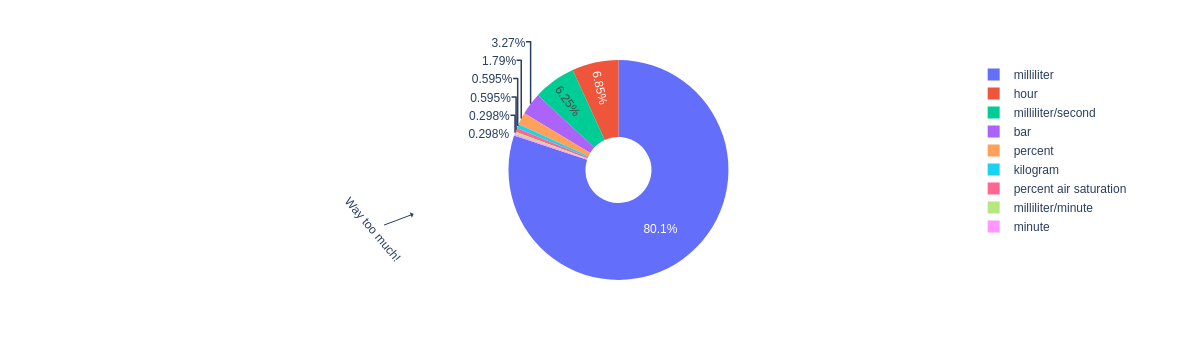

In [6]:
fig = px.pie(results_df.groupby('canonical_unit').count().reset_index(), values='raw_label', names='canonical_unit', hole=0.3, width=500)
fig.add_annotation(x=0.2, y=0.3,
            text="Way too much!",
            showarrow=True,
            arrowhead=1,
            textangle = 50,
                  ax=-40,
                  ay=15)

### Calculate Accuracy
Now we can compare each automatically-labeled answer one-to-one with the correct answer.

I want to calculate the accuracy for 6 total conditions:
* **All rows**: How accurate would we be if we took whatever output the model gave us?
* **Confident rows**: What if we considered only the rows that the model was confident about (and assumed unconfident rows would be manually labeled)?
* **Unconfident rows**: Is the model really less accurate when it reports low confidence?
* **Defined rows**: We know our ontology is bad - to simulate having a better one, what is the accuracy if we exclude any row where the human was unable to give a definitive label?
* **Confident & Defined rows**: Of the defined subset, how accurate would we be if we only looked at the confident rows?
* **Unconfident & Defined rows**: Of the defined subset, how accurate is the model when it reports low confidence? Curious how this changes when we remove entries that the model has no way of being confident about.

For each of these conditions, we want to look at each of the remaining 4 labels we had the model apply (since we tossed out `units`). We also want to look at the labels holistically - how often does the model get every label correct and we don't even how to look at that row?

In [7]:
CANONICAL_QUESTIONS = ['canonical_name', 'canonical_submeasurement', 'canonical_process_location', 'canonical_signal_type']
questions = CANONICAL_QUESTIONS + ['correct_overall']

CONFIDENCE_THRESHOLD = 0.5

# Each entry becomes one labeled column of the summary table below: the column name
# is the label, and the value is what to pass to `calculate_percent_correct`.
CONFIDENCE_GATES = {
    'all_rows': {},
    'confident_rows': {'confidence_threshold': CONFIDENCE_THRESHOLD},
    'unconfident_rows': {'confidence_threshold': CONFIDENCE_THRESHOLD, 'confident': False},
    'defined_rows': {'include_undefined': False},
    'confident_defined_rows': {'confidence_threshold': CONFIDENCE_THRESHOLD, 'include_undefined': False},
    'unconfident_defined_rows': {'confidence_threshold': CONFIDENCE_THRESHOLD, 'confident': False, 'include_undefined': False},
}


def calculate_percent_correct(df: pd.DataFrame, question: str, confidence_threshold: float = None, confident: bool = True, include_undefined: bool = True) -> float:
    """Fraction of `df` rows where the prediction for `question` matches ground truth.

    The denominator is always the rows you hand in, so the answer is the same however
    you filtered `df`.

    confidence_threshold: score only the rows this question was (or wasn't) confident
        about, using *that question's own* confidence column instead of one row-level
        flag.
    confident: set False to invert the gate and score the low-confidence rows instead.
    include_undefined: set False to remove any entry where the correct is "[UNDEFINED]"
        from the calculation.

    Returns NaN when nothing is left to score, so a chart shows a gap rather than a
    misleading 0.
    """
    if confidence_threshold is not None:
        if question == 'correct_overall':
            keep = (df[[q + '_confidence' for q in CANONICAL_QUESTIONS]] >= confidence_threshold).all(axis=1) #equivalent to the needs_review column
        else:
            keep = df[question + '_confidence'] >= confidence_threshold
        df = df.loc[keep if confident else ~keep]

    if not include_undefined:
        if question == 'correct_overall':
            keep = (df[['correct_' + q.removeprefix('canonical_') for q in CANONICAL_QUESTIONS]] != "[UNDEFINED]").all(axis=1) #equivalent to the needs_review column
        else:
            keep = df['correct_' + question.removeprefix('canonical_')] != "[UNDEFINED]"
        df = df.loc[keep]

    if not len(df):
        return float('nan')

    if question == 'correct_overall':
        return float(df[question].mean())  # already a precomputed is-correct flag

    return float((df[question] == df['correct_' + question.removeprefix('canonical_')]).mean())


# One row per question, one labeled column per confidence gate.
percent_correct_df = pd.DataFrame({
    gate: {q: calculate_percent_correct(results_df, q, **kwargs) for q in questions}
    for gate, kwargs in CONFIDENCE_GATES.items()
})

percent_correct_df

,all_rows,confident_rows,unconfident_rows,defined_rows,confident_defined_rows,unconfident_defined_rows
canonical_name,0.602941,0.825893,0.172414,0.676568,0.848624,0.235294
canonical_submeasurement,0.717647,0.825532,0.476190,0.853147,0.885845,0.746269
canonical_process_location,0.576471,0.901042,0.155405,0.664407,0.950549,0.203540
canonical_signal_type,0.920588,0.953488,0.666667,0.923304,0.956667,0.666667
correct_overall,0.264706,0.670213,0.109756,0.373444,0.732558,0.174194


This will be easier to conceptualize if we plot it.

### Plot

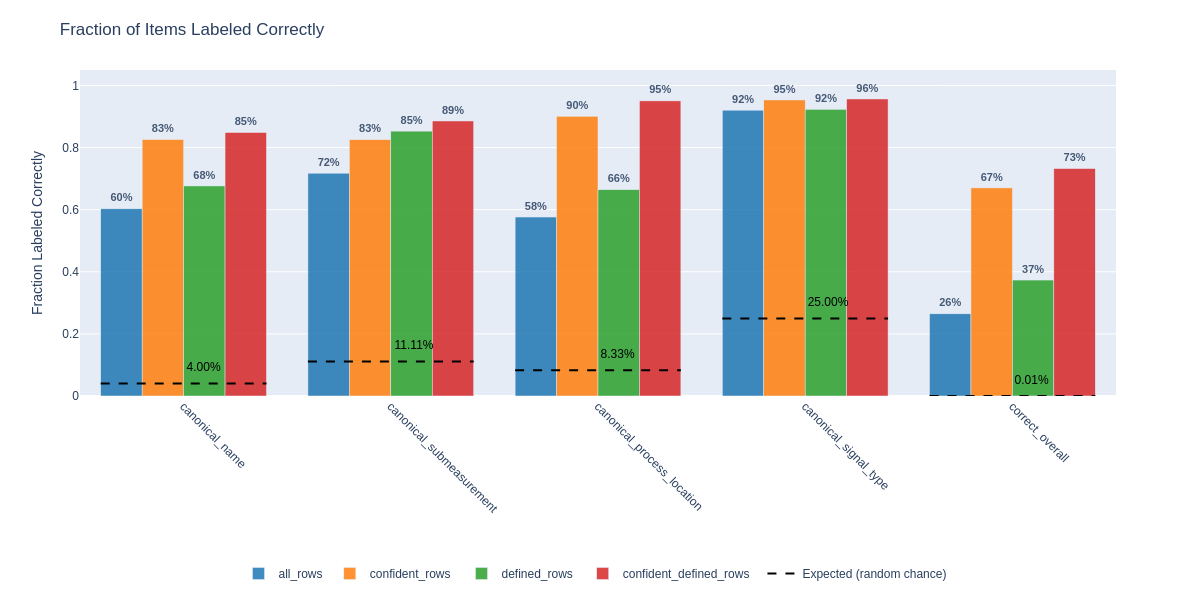

In [8]:
#NOTE: If you skipped here and didn't do the inference, you will still need to run the cell above the inference cell
#      because we use some of the variables defined there.

expected_values = {
    'canonical_name': 1/len(name_df),
    'canonical_submeasurement': 1/len(submeasurement_df),
    'canonical_process_location': 1/len(location_df),
    'canonical_signal_type': 1/len(signal_type_df),
    'correct_overall': 1/len(name_df) * 1/len(submeasurement_df) * 1/len(location_df) * 1/len(signal_type_df)
}

def plot_grouped_bar_chart(df: pd.DataFrame, random_chance: dict | None = None, title: str = 'Fraction of Items Labeled Correctly',
                           ylabel: str = 'Fraction Labeled Correctly', value_format: str = '{:.0%}') -> None:
    """One group of bars per row of `df`, one distinctly-colored bar per column.

    `title`, `ylabel`, and `value_format` are parameters so the same charting code can render
    any 0-1 fraction - accuracy here, confidence coverage below - instead of being hardcoded
    to one wording. The defaults reproduce the original accuracy chart exactly.
    """
    # Plotly Express draws one bar per row of the frame it is handed, so melt the wide
    # frame into (group, series, value) triples: one row per bar, one series per column.
    long_df = (
        df.rename_axis(index='group')
          .reset_index()
          .melt(id_vars='group', var_name='series', value_name='value')
    )

    # Bar labels are formatted up front so `value_format` still drives them. NaN means
    # nothing was left to score: plotly draws that as a gap, so it gets no label either.
    long_df['label'] = long_df['value'].map(lambda value: '' if pd.isna(value) else value_format.format(value))

    fig = px.bar(
        long_df, x='group', y='value', color='series',
        barmode='group',  # bars for the same group sit side by side, one color per column
        text='label',
        title=title,
        labels={'group': '', 'series': '', 'value': ylabel},  # no axis or legend titles
        color_discrete_sequence=px.colors.qualitative.D3,  # tab10, as before; cycles automatically if a gate is added
        width=1200, height=600,  # same footprint as the old figsize=(12, 6)
    )

    fig.update_traces(opacity=0.85, textposition='outside', textfont={'size': 11, 'weight': 'bold'})
    fig.update_xaxes(tickangle=45, categoryorder='array', categoryarray=list(df.index))  # keeps the frame's row order
    fig.update_yaxes(range=[0, 1.05])

    # Reference lines for the expected values. Shapes are drawn in axis coordinates and, on a
    # categorical axis, those coordinates are group indices - so a line from i-0.4 to i+0.4
    # spans exactly one group: the same 80% of the slot that the bars fill.
    if random_chance:
        group_half_width = 0.4

        for i, idx in enumerate(df.index):
            expected_val = random_chance.get(idx)  # matched by label, so ordering can't drift
            if expected_val is None:
                continue

            left_edge, right_edge = i - group_half_width, i + group_half_width

            fig.add_shape(type='line', xref='x', yref='y',
                          x0=left_edge, x1=right_edge, y0=expected_val, y1=expected_val,
                          line={'color': 'black', 'dash': 'dash', 'width': 2})
            fig.add_annotation(x=(left_edge + right_edge) / 2, y=expected_val + 0.02,
                               text=f'{expected_val:.2%}', showarrow=False,
                               xanchor='left', yanchor='bottom', font={'size': 12, 'color': 'black'})

        # Shapes get no legend entry in plotly, so a single null point carries that swatch
        # (an entirely empty trace would be dropped from the legend).
        fig.add_trace(go.Scatter(x=[None], y=[None], mode='lines', name='Expected (random chance)',
                                 line={'color': 'black', 'dash': 'dash', 'width': 2}))

    # Legend goes below the plot, where it can never cover a bar. Anchoring it to the
    # container lets plotly grow the bottom margin itself to fit both it and the angled
    # tick labels; only the template's oversized top margin needs trimming back.
    fig.update_layout(
        legend={'orientation': 'h', 'xanchor': 'center', 'x': 0.5,
                'yref': 'container', 'yanchor': 'bottom', 'y': 0.02},
        margin={'t': 70},
    )

    fig.show()

plot_grouped_bar_chart(percent_correct_df[['all_rows','confident_rows', 'defined_rows', 'confident_defined_rows']], expected_values)


Hey, that's pretty good for a zero-shot! If we were to trust the model completely when it reported a confidence >0.5, and assuming we had a good ontology, **we would have labeled the entire row correctly 73% of the time.**

We also see that there is generally a big jump in accuracy between the high- and low-confidence numbers, suggesting to me that the confidence value the model reports is actually useful. We may get better results if we tune our cutoff value, since 0.5 was an arbitrary choice.

Looking at each column independently, we see that no one column seems to be driving the inaccuracy - the appear to be independent. Process Location is the least accurate, but improves greatly when we only look at confident guesses. That makes sense, because most labels don't have information about _where_ the measurement is happening - you have to infer from where, say, a pH probe is generally positioned in a bioreactor. This is niche contextual knowledge that the model wouldn't have.

The name column also didn't do as well as I'd hoped. Looking at the data, one failure mode seems to be as simple as single letters confusing it - "Pump A" seems to be labeled "Air" and "Pump C" seems to be labeled "Carbon Dioxide" more than I would expect. I'm not sure how to get around that without retraining.

Also, 54 out of 340 (~15%) of the rows were labeled "Steam" even though that is never the correct answer. Something in the prompt seems to make it something of an attractor. It's possible that improvements in the prompt, or removing it as an option (because we know this equipment doesn't have a steam line) would get us dramatically better results.



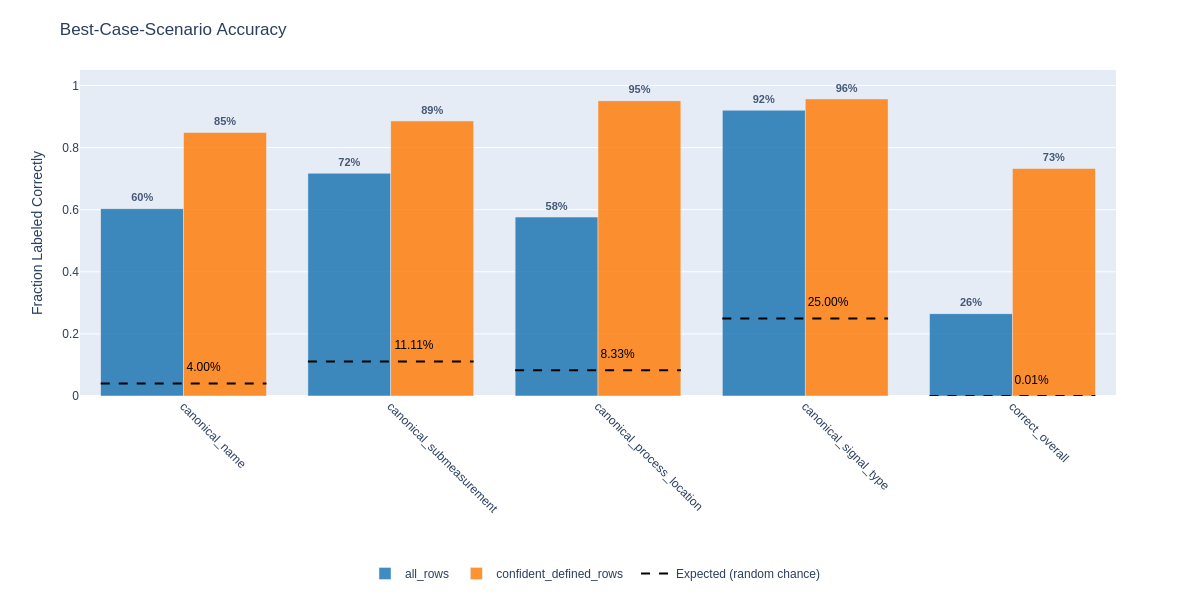

In [9]:
plot_grouped_bar_chart(percent_correct_df.loc[:,['all_rows', 'confident_defined_rows']], expected_values, title = 'Best-Case-Scenario Accuracy')

## Plot proportion of confident and undefined answers

The percentage of labels that are correct when the model reports being confidence is really pretty good for a zero-shot approach. But if most answers aren't confident then it still means we have a lot of review to do.

Denominator for every bar: all 340 labeled rows


,confidence >= 0.5
canonical_name,0.658824
canonical_submeasurement,0.691176
canonical_process_location,0.564706
canonical_signal_type,0.885294
all_questions,0.276471


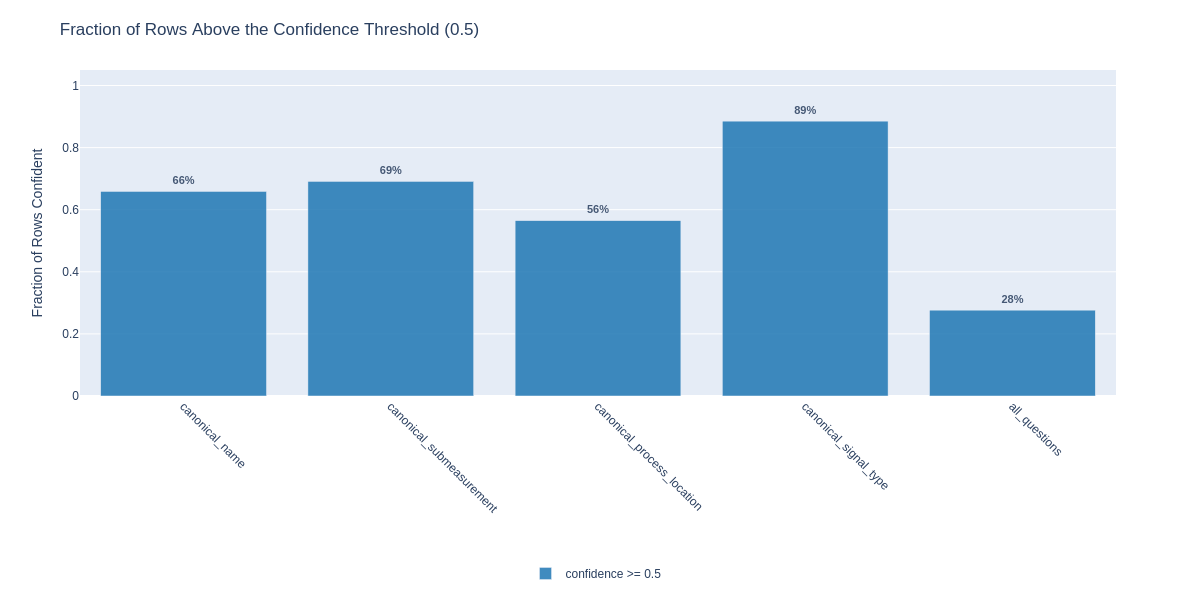

In [10]:
print(f'Denominator for every bar: all {len(results_df)} labeled rows')

# Confidence is reported per question, so each question gets its own bar. `all_questions`
# is the row-level gate: the share of rows clearing the threshold on *every* question at
# once - i.e. exactly the rows that don't get flagged `needs_review`.
confidence_columns = [question + '_confidence' for question in CANONICAL_QUESTIONS]
is_confident_df = results_df[confidence_columns] >= CONFIDENCE_THRESHOLD  # a missing score counts as unconfident

# `.mean()` of a boolean frame is just the fraction of True rows, so this is fully vectorized.
percent_confident = is_confident_df.mean().rename(index=lambda column: column.removesuffix('_confidence'))
percent_confident['all_questions'] = is_confident_df.all(axis=1).mean()

percent_confident_df = percent_confident.to_frame(f'confidence >= {CONFIDENCE_THRESHOLD}')
display(percent_confident_df)

plot_grouped_bar_chart(
    percent_confident_df,
    title=f'Fraction of Rows Above the Confidence Threshold ({CONFIDENCE_THRESHOLD})',
    ylabel='Fraction of Rows Confident',
    value_format='{:.0%}',  # bars read as percentages; values stay 0-1 so the axis matches the chart above
)

Looks like we lose about a third of the rows in each column to low confidence. Not great for a production system, but enough to feel like there's some value here.

#### Undefined

I also want to account for the cases where I feel that it was my bad ad hoc ontology that is at fault. If the model had no good choices - because even I as a domain expert couldn't fit the label into one of the options - then we should remove those cases from the dataset to get a better sense of how the model would perform if it had an appropriate ontology and lexicon to work from.

We can see from our plot above that removing the undefined cases generally improves the fraction that is correct. But if we had *mostly* undefined, that would make the improvement less meaningful because the sample size would be too small. Let's double-check.

Denominator for every bar: all 340 labeled rows


,is defined
name,0.891176
submeasurement,0.841176
process_location,0.867647
signal_type,0.997059
all_questions,0.708824


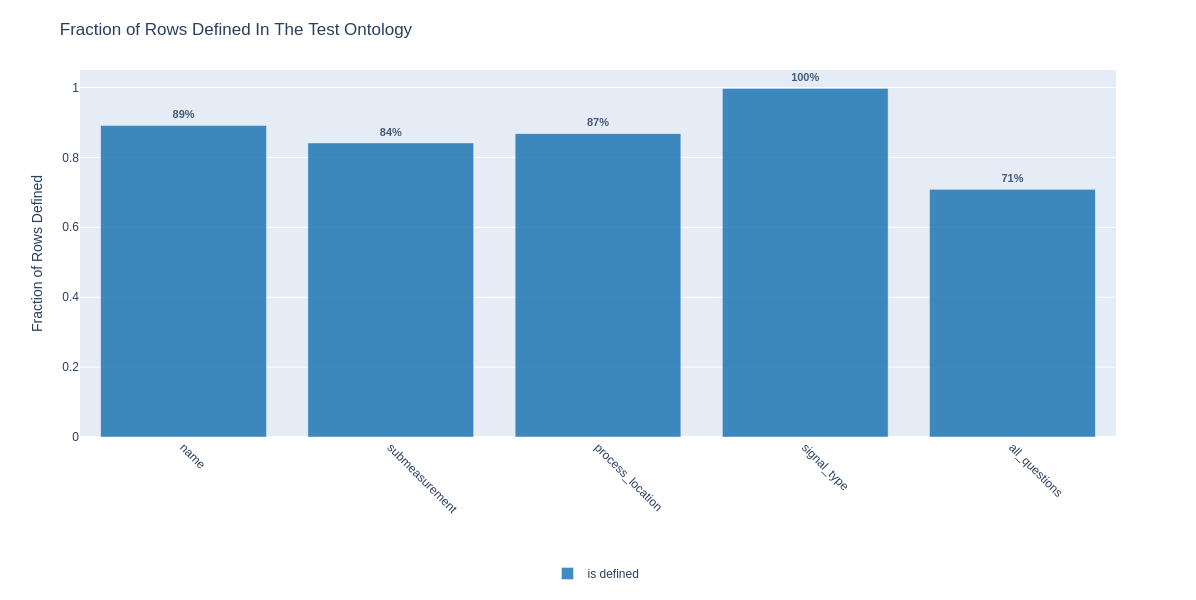

In [11]:
print(f'Denominator for every bar: all {len(results_df)} labeled rows')

# Confidence is reported per question, so each question gets its own bar. `all_questions`
# is the row-level gate: the share of rows clearing the threshold on *every* question at
# once - i.e. exactly the rows that don't get flagged `needs_review`.
correct_columns = ['correct_' + question.removeprefix('canonical_') for question in CANONICAL_QUESTIONS]
is_defined_df = results_df[correct_columns] != "[UNDEFINED]"

# `.mean()` of a boolean frame is just the fraction of True rows, so this is fully vectorized.
percent_defined = is_defined_df.mean().rename(index=lambda column: column.removeprefix('correct_'))
percent_defined['all_questions'] = is_defined_df.all(axis=1).mean()

percent_defined_df = percent_defined.to_frame('is defined')
display(percent_defined_df)

plot_grouped_bar_chart(
    percent_defined_df,
    title='Fraction of Rows Defined In The Test Ontology',
    ylabel='Fraction of Rows Defined',
    value_format='{:.0%}',  # bars read as percentages; values stay 0-1 so the axis matches the chart above
)

Only about 15% couldn't be squeezed into this ontology. Given that, I think our conclusions are still valid, considering we're just exploring a proof-of-concept.

### Calculate Effort Savings

In real life, how much this helps us depends on exactly how we're labelling the data. My initial question was "How much will this help us if we just throw the model at it without doing anything else?", so I'm going to assume for this calculation that we're a single, stressed-out data scientist who has a big spreadsheet and needs to get it normalized before doing any other work. So they would like to automate the labelling, but will be able to review the output and manually enter values where the model wasn't confident and correct values where the model was wrong.

If we model our workflow that way, we can calculate the percent of entries we've labeled automatically with no further effort required as:
$$\%saved\_from\_review = \frac{\sum_{cols} (\%correct\_defined\_confident \cdot num\_confident\_defined)}{\sum_{cols} (num\_defined)}$$

Calculating that:

In [12]:
pct_entries_not_needing_review = percent_correct_df.iloc[:-1]['confident_defined_rows'].rename(index=lambda column: column.removeprefix('canonical_'))
num_confident_defined_entries = (
        is_confident_df.rename(columns=lambda x: x.removeprefix('canonical_').removesuffix('_confidence')) &
        is_defined_df.rename(columns=lambda x: x.removeprefix('correct_'))
    ).replace(False,np.nan).count()
num_defined_entries = is_defined_df.replace(False,np.nan).count().rename(index=lambda column: column.removeprefix('correct_'))

num_entries_not_needing_review = pct_entries_not_needing_review * num_confident_defined_entries

total_entries_not_needing_review = num_entries_not_needing_review.sum()
total_defined_entires = num_defined_entries.sum()

pct_saved_from_labelling = total_entries_not_needing_review / total_defined_entires

print(f"""Accounting for data that can't be described in our ontology,
and assuming that we only label incorrect and/or unconfident entries,
we've saved:
{pct_saved_from_labelling:0.01%}
of the labelling work

Good for us!""")


Accounting for data that can't be described in our ontology,
and assuming that we only label incorrect and/or unconfident entries,
we've saved:
68.6%
of the labelling work

Good for us!


#### Plot It

We can make a stacked bar chart that shows the three practical outcomes we get when using the model to automate labelling data this way:

* the labels the model got right that nobody had to touch,
* the labels it got wrong while reporting confidence - the silent errors we'd be accepting,
* the labels it flagged as low-confidence and handed back to a human.

To compare, we'll also do the math on the case where we just randomly guess for each decision and, since most of the data is biased towards one outcome (`PV` is by far the dominant value for `signal_type`), let's also compare to a case where we just guess the modal answer for every decision.

A better comparison would be either comparing accuracy and cost to a frontier LLM model, or comparing developer time to a traditional model. But we don't have either set of data, so we'll work with what we've got!


In [19]:
total_confident_defined_entries = num_confident_defined_entries.sum()

chance_saved_entries = (
    pd.Series(expected_values)
      .drop('correct_overall')  # that entry is the product across questions, not a per-question rate
      .rename(index=lambda question: question.removeprefix('canonical_'))  # match num_defined_entries' index
    * num_defined_entries
).sum()

pct_saved_by_random_chance = chance_saved_entries / total_defined_entires

majority_class_saved_entries = pd.Series({
    question.removeprefix('correct_'):
        results_df.loc[is_defined_df[question], question].value_counts().iloc[0]
    for question in is_defined_df.columns
}).sum()

pct_saved_by_majority_class = majority_class_saved_entries / total_defined_entires

silent_errors_from_labelling = total_confident_defined_entries - total_entries_not_needing_review
silent_errors_by_majority_class = total_defined_entires - majority_class_saved_entries

effort_outcome_df = pd.DataFrame(
    {'labels': [
        total_entries_not_needing_review,                                   # trusted, and correct
        total_confident_defined_entries - total_entries_not_needing_review, # trusted, but wrong
        total_defined_entires - total_confident_defined_entries,            # never trusted
    ]},
    index=[
        'labeled correctly - no human effort',
        'labeled incorrectly - silently trusted',
        'Low confidence - routed to a human',
    ],
)

effort_outcome_df['labels'] = effort_outcome_df['labels'].round().astype(int)
effort_outcome_df['share'] = effort_outcome_df['labels'] / effort_outcome_df['labels'].sum()

display(effort_outcome_df)

print(f"""Both baselines get handed the same "trust every answer" policy the model got:

  uniform random over each ontology   -> {pct_saved_by_random_chance:5.1%} saved  ({pct_saved_from_labelling / pct_saved_by_random_chance:.1f}x lift)
  always guess the most common label  -> {pct_saved_by_majority_class:5.1%} saved  ({pct_saved_from_labelling / pct_saved_by_majority_class:.1f}x lift)

  the model itself                    -> {pct_saved_from_labelling:5.1%} saved, with {silent_errors_from_labelling:.0f} silent errors
""")


,labels,share
labeled correctly - no human effort,839,0.686018
labeled incorrectly - silently trusted,80,0.065413
Low confidence - routed to a human,304,0.248569


Both baselines get handed the same "trust every answer" policy the model got:

  uniform random over each ontology   -> 12.5% saved  (5.5x lift)
  always guess the most common label  -> 40.9% saved  (1.7x lift)

  the model itself                    -> 68.6% saved, with 80 silent errors



In [20]:
majority_class_saved_rounded = int(majority_class_saved_entries)  # already whole, but pin the type

OUTCOME_ORDER = list(effort_outcome_df.index)  # green, red, grey - the stack order the plot draws

# Not plotting uniform random guessing because it doesn't add to the story
strategy_outcome_counts = {
    'Decision Model': effort_outcome_df['labels'].to_dict(),
    'Best Fixed Guess': {
        OUTCOME_ORDER[0]: majority_class_saved_rounded,
        OUTCOME_ORDER[1]: total_defined_entires - majority_class_saved_rounded,
        OUTCOME_ORDER[2]: 0,
    },
}

strategy_outcome_df = pd.DataFrame([
    {'strategy': strategy, 'outcome': outcome, 'labels': counts[outcome]}
    for strategy, counts in strategy_outcome_counts.items()
    for outcome in OUTCOME_ORDER
])

strategy_outcome_df['share'] = (
    strategy_outcome_df['labels']
    / strategy_outcome_df.groupby('strategy')['labels'].transform('sum')
)

strategy_outcome_summary_df = strategy_outcome_df.pivot(
    index='strategy', columns='outcome', values='labels'
).reindex(index=list(strategy_outcome_counts), columns=OUTCOME_ORDER)
strategy_outcome_summary_df['bar total'] = strategy_outcome_summary_df.sum(axis=1)

display(strategy_outcome_summary_df)


outcome,labeled correctly - no human effort,labeled incorrectly - silently trusted,Low confidence - routed to a human,bar total
strategy,,,,
Decision Model,839,80,304,1223
Best Fixed Guess,500,723,0,1223


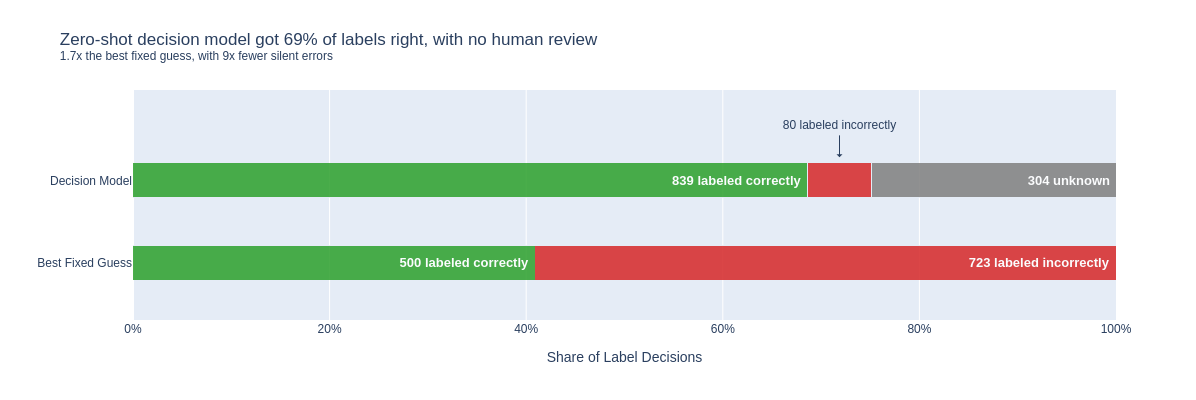

In [25]:
def plot_strategy_comparison(outcome_df: pd.DataFrame,
                             title: str = 'Share of Label Decisions By Outcome, Per Strategy',
                             xlabel: str = 'Share of Label Decisions',
                             thin_segment_cutoff: float = 0.15) -> None:
    """One horizontal bar per labelling strategy, every bar covering the same decisions.

    outcome_df: tidy rows of `strategy`, `outcome`, `labels`, `share`. Within a strategy, row
        order is stack order; across strategies, row order is top-to-bottom as drawn, since the
        y axis is flipped below. Every strategy must cover the same decisions - that shared
        denominator is the entire basis of the comparison, and the cell above displays it.
    thin_segment_cutoff: segments narrower than this get no inside text - the words would spill
        outside the segment - and get called out from above with an arrow instead.
    """
    segment_words = {
        'labeled correctly - no human effort': 'labeled correctly',
        'labeled incorrectly - silently trusted': 'labeled incorrectly',
        'Low confidence - routed to a human': 'unknown',
    }

    long_df = outcome_df.copy()

    # Bar order as drawn. `dict.fromkeys` de-duplicates while preserving first-appearance order,
    # so this is the frame's strategy order - which the flipped y axis renders top to bottom.
    strategy_order = list(dict.fromkeys(long_df['strategy']))

    long_df['label'] = [
        '' if labels == 0 or share < thin_segment_cutoff else f'{labels:,} {segment_words[outcome]}'
        for labels, share, outcome
        in zip(long_df['labels'], long_df['share'], long_df['outcome'])
    ]

    fig = px.bar(
        long_df, x='share', y='strategy', color='outcome',
        orientation='h',
        barmode='stack',  # segments lay end to end, so every bar totals 100%
        text='label',
        title=title,
        labels={'strategy': '', 'outcome': '', 'share': xlabel},  # no axis or legend titles
        color_discrete_map={
            'labeled correctly - no human effort': '#2ca02c',
            'labeled incorrectly - silently trusted': '#d62728',
            'Low confidence - routed to a human': '#7f7f7f',
        },
        width=1200, height=400,
    )

    fig.update_traces(opacity=0.85, width=0.42, textposition='inside',
                      insidetextfont={'size': 13, 'weight': 'bold', 'color': 'white'})
    fig.update_xaxes(range=[0, 1], tickformat='.0%')
    # A descending range flips the category axis, so the model - the frame's first strategy -
    # reads at the top and the baseline sits below it. The padding above the top slot is room
    # for its callout; the padding below keeps the baseline bar clear of the axis.
    fig.update_yaxes(range=[1.7, -1.1], showgrid=False)


    # Segments too narrow to hold their own text get called out from above instead. The callout
    # carries both its y category and the x midpoint of its own segment - and, because the axis
    # is flipped, sits at a _smaller_ y than its bar to land visually above it.
    for strategy, group in long_df.groupby('strategy', sort=False):
        # Position of this bar top-to-bottom, from the de-duplicated strategy order rather than
        # from `long_df`: the frame holds one row per outcome, so a naive `.index(strategy)`
        # would return a row position several times too large.
        row = strategy_order.index(strategy)
        cumulative_share = 0.0
        for labels, share, outcome in zip(group['labels'], group['share'], group['outcome']):
            midpoint = cumulative_share + share / 2
            cumulative_share += share

            # Zero is not "thin", it's absent: the baseline has no grey segment at all, and
            # calling out a segment that isn't drawn would leave a stray "0 unknown" note.
            if labels == 0 or share >= thin_segment_cutoff:
                continue

            fig.add_annotation(x=midpoint, y=row - 0.28,
                               text=f'{labels:,} {segment_words[outcome]}',
                               showarrow=True, arrowhead=1, ax=0, ay=-22,
                               yanchor='bottom', font={'size': 12})

    fig.update_layout(showlegend=False, margin={'t': 90})

    fig.show()

plot_strategy_comparison(
    strategy_outcome_df,
    title=(
        f'Zero-shot decision model got {pct_saved_from_labelling:.0%} of labels right, with no human review'
        f'<br><sup>{pct_saved_from_labelling / pct_saved_by_majority_class:.1f}x the best '
        f'fixed guess, with '
        f'{silent_errors_by_majority_class / silent_errors_from_labelling:.0f}x fewer silent '
        f'errors</sup>'
    ),
)


This looks great, but obviously this is just a proof-of-concept and there are several caveats:

* **This is a per-label saving, not a per-row one.** Only 94 of the 340 rows (28%) clear the confidence threshold on all four questions at once, so only about a quarter of rows escape review entirely. The bars count label _decisions_, which is the right unit for one stressed-out person working down a spreadsheet - accepting three of four suggested labels is much faster than creating four - but it is not the same claim as "28% of rows need no attention."
* **137 of the 1,360 decisions (10%) aren't on these bars at all**, because I couldn't squeeze them into my own ad hoc ontology. In practice, we may find even a very good ontology fails to describe some measurements, so we should at some point reckon with how the model handles this situation.
* **This is one reactor directory** (`Data/00001/B/01`), and the ground truth is my own hand-labelling of it. It's a small amount of data, from exactly one manufacturer and, although it can be hard to read, AMBR _is_ very detailed in its data reporting. Further, I did my best with labelling, but it's nothing like trying to get an entrie organization or entire field to agree on the appropriate meaning of these labels.
* **The 0.5 confidence threshold was arbitrary and untuned**, so 6% silent errors isn't a floor. A tuned cutoff would trade the green and red segments against each other rather than landing wherever 0.5 happened to fall.


## Takeaways

Overall, this is useful as a first pass in a scenario where you have a lot of data and some other process for validation and correction.

1. For manual data entry, it's correct enough that you can go back over and manually fix its outputs and still save time
2. For an automated system where it's impractical to do human review, the output could be passed to a downstream model for validation and correction - could be an LLM, a numerical tool that uses heuristics, or just a set of deterministic rules.

In both cases, but especially #2, you'll want to get more confidence and higher accuracy on those condfident answers if you want to use this long-term. I think there's some low-hanging fruit:

* Use a better ontology so that we're not asking the model to do the impossible
* Fine-tune the model to be more familiar with the niche lexicon and labelling practices in biotechnology
* Integrate a numerical analysis model that can look at the datastreams themselves and corroborate or raise questions about the label

With all three implemented, I expect much higher accuracies and confidence are possible, and such a system could automate most labelling for this kind of data with only periodic human review necessary.